# Disease Prediction from Medical Data (UCI Heart Disease, Cleveland)

**CodeAlpha Machine Learning Internship, Task 4**
Author: Omar Abdelhady

Goal: predict whether a patient has heart disease from structured clinical data (age, chest pain type, resting blood pressure, cholesterol, exercise test results, fluoroscopy findings) using four classifiers: Logistic Regression, SVM, Random Forest and XGBoost.

> **Educational model only. Not for clinical use.** It is trained on 303 patients from one hospital in the 1980s and has not been validated on any other population.

Outline
1. Setup
2. Load the data (in code, verified)
3. Missing values and target definition
4. Exploratory data analysis
5. Preprocessing with leakage-free pipelines
6. Model tuning and nested cross-validation
7. Test-set evaluation
8. Decision threshold for a medical setting (recall first)
9. Interpretability (feature importance and SHAP)
10. Limitations

In [1]:
# ---- 1. Setup -------------------------------------------------------------
import hashlib, io, json, platform, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
# shap imports tqdm, which warns when ipywidgets is absent; this is cosmetic only
warnings.filterwarnings("ignore", message="IProgress not found")
import sklearn, xgboost, shap
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

SEED = 42                         # one seed everywhere so every number is reproducible
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

print("Python", platform.python_version(), "| sklearn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| shap", shap.__version__, "| pandas", pd.__version__)

Python 3.13.16 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.52.0 | pandas 3.0.5


## 2. Load the data

The notebook downloads the original UCI file `processed.cleveland.data` so the repo needs no manual download. It tries the official UCI URL first and falls back to a GitHub copy of the same file if UCI is unreachable (UCI has had outages). Whichever source is used, the content is checked against the facts published in UCI's `heart-disease.names`: 303 rows, 14 columns, missing values marked with `?`, and the class counts of `num` (0: 164, 1: 55, 2: 36, 3: 35, 4: 13). If any check fails the notebook stops instead of training on the wrong data.

Column meanings (from the UCI documentation):

| column | meaning | type |
|---|---|---|
| age | age in years | numeric |
| sex | 1 = male, 0 = female | binary |
| cp | chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic | categorical |
| trestbps | resting blood pressure (mm Hg) | numeric |
| chol | serum cholesterol (mg/dl) | numeric |
| fbs | fasting blood sugar > 120 mg/dl | binary |
| restecg | resting ECG: 0 normal, 1 ST-T abnormality, 2 left ventricular hypertrophy | categorical |
| thalach | maximum heart rate achieved | numeric |
| exang | exercise-induced angina | binary |
| oldpeak | ST depression induced by exercise relative to rest | numeric |
| slope | slope of peak exercise ST segment: 1 up, 2 flat, 3 down | categorical |
| ca | number of major vessels (0 to 3) colored by fluoroscopy | ordinal count |
| thal | thallium stress test: 3 normal, 6 fixed defect, 7 reversible defect | categorical |
| num | diagnosis: 0 = no disease, 1 to 4 = disease present | target |

In [2]:
# ---- 2. Load the data -----------------------------------------------------
UCI_URL = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
           "heart-disease/processed.cleveland.data")
# Public GitHub copy of the same UCI file, used only if UCI is unreachable.
# The content checks below guarantee it matches the documented UCI data.
MIRROR_URL = ("https://raw.githubusercontent.com/amiralansary/Heart-Disease-Diagnosis/"
              "master/data/processed.cleveland.data")
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]


def download(url, timeout=30):
    with urllib.request.urlopen(url, timeout=timeout) as r:
        return r.read()


def load_cleveland():
    raw, source = None, None
    for url in (UCI_URL, MIRROR_URL):
        try:
            raw, source = download(url), url
            break
        except Exception as e:                      # network error, try the next source
            print(f"Could not download {url}: {e}")
    if raw is None:
        raise RuntimeError("Dataset could not be downloaded from UCI or the mirror.")

    # '?' marks missing values in this file
    df = pd.read_csv(io.BytesIO(raw), header=None, names=COLUMNS, na_values="?")

    # Content checks against the UCI documentation, so a wrong file can never slip through
    assert df.shape == (303, 14), df.shape
    assert df.isna().sum().to_dict() == {**{c: 0 for c in COLUMNS}, "ca": 4, "thal": 2}
    assert df["num"].value_counts().sort_index().tolist() == [164, 55, 36, 35, 13]
    print("Source :", source)
    print("SHA-256:", hashlib.sha256(raw).hexdigest())
    return df


df_raw = load_cleveland()
df_raw.head()

Could not download https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data: <urlopen error Tunnel connection failed: 403 Forbidden>


Source : https://raw.githubusercontent.com/amiralansary/Heart-Disease-Diagnosis/master/data/processed.cleveland.data
SHA-256: a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.439,9.039,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.680,0.467,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158,0.960,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.690,17.600,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693,51.777,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.149,0.356,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990,0.995,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607,22.875,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.327,0.470,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.040,1.161,0.0,0.0,0.8,1.6,6.2


## 3. Missing values and target definition

**Missing values.** Only 6 values are missing: 4 in `ca` and 2 in `thal`, spread over 6 patients (2% of rows).

How they are handled, and why:
- I keep the rows and impute rather than drop them. Dropping would be defensible at 2%, but imputing inside the pipeline is the general, leakage-safe pattern and keeps the sample size intact on an already small dataset.
- `thal` is categorical, so it gets the **most frequent** category. `ca` is a small integer count (0 to 3) with a skewed distribution, so it gets the **median**, which also stays a valid count. Mean imputation would produce a non-integer and be pulled by the skew.
- The imputers sit **inside the sklearn Pipeline**, so the most-frequent value and the median are learned from the training data only (and from the training folds only during cross-validation). The test set never influences them.

**Target.** The original `num` column is 0 (no disease) to 4 (increasing severity). Following the standard use of this dataset and the UCI description (experiments concentrate on presence vs absence), I binarize it: `target = 1 if num > 0 else 0`. The severity grades 1 to 4 have only 13 to 55 patients each, too few to model reliably as separate classes, and the task brief asks for the possibility of disease, which is a yes/no question.

Missing values per column: {'ca': 4, 'thal': 2}
Rows with any missing value: 6 of 303

Class balance: {0: 164, 1: 139} | share with disease = 0.459


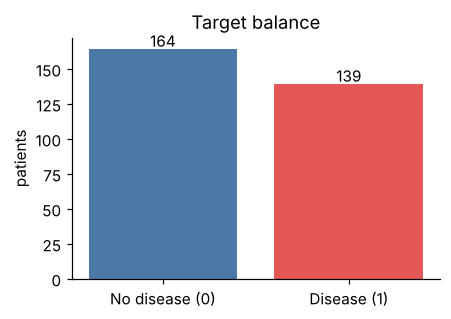

In [4]:
# ---- 3. Missing values and target -----------------------------------------
na = df_raw.isna()
print("Missing values per column:", na.sum()[na.sum() > 0].to_dict())
print("Rows with any missing value:", int(na.any(axis=1).sum()), "of", len(df_raw))

df = df_raw.copy()
df["target"] = (df["num"] > 0).astype(int)   # 1 = disease present
df = df.drop(columns="num")                  # drop the original grade so it cannot leak

counts = df["target"].value_counts().sort_index()
print("\nClass balance:", counts.to_dict(),
      "| share with disease = %.3f" % df["target"].mean())

fig, ax = plt.subplots(figsize=(4.2, 3))
ax.bar(["No disease (0)", "Disease (1)"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center")
ax.set_ylabel("patients"); ax.set_title("Target balance")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_balance.png"); plt.show()

The classes are close to balanced (about 54% / 46%), so no resampling is needed. Stratified splitting will keep this ratio in every split and fold.

## 4. Exploratory data analysis

Two figures: distributions of the numeric features split by diagnosis, and the disease rate within each level of the categorical features. A small table then ranks every feature by its rank correlation with the target. EDA here uses the full dataset because it only describes the data; no modelling decision is fitted on it.

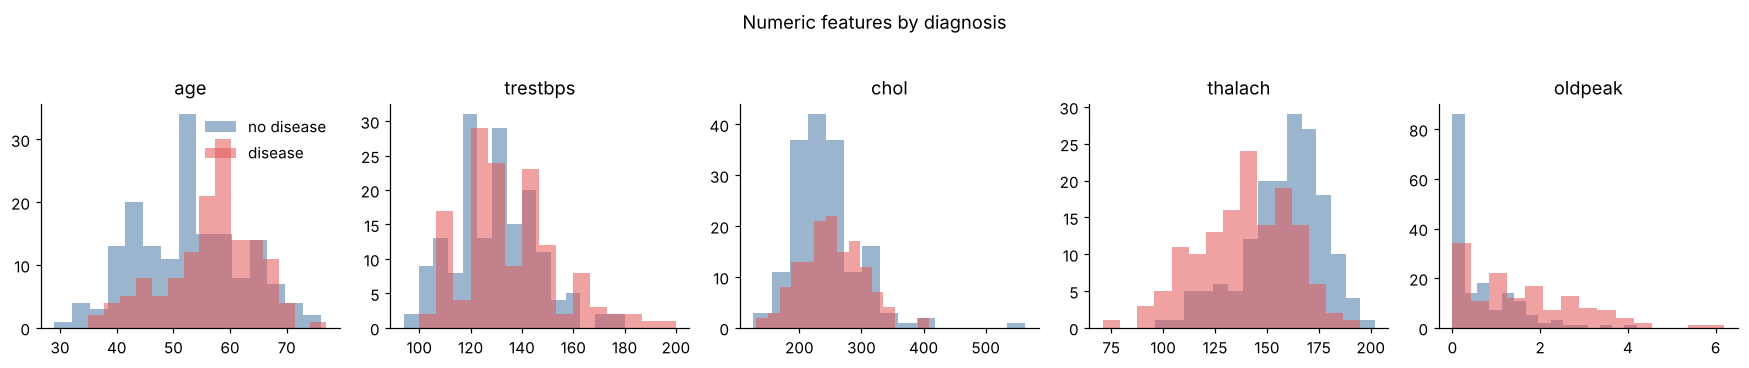

,age,trestbps,chol,thalach,oldpeak
target,,,,,
"median, no disease",52.0,130.0,234.5,161.0,0.2
"median, disease",58.0,130.0,249.0,142.0,1.4


In [5]:
# ---- 4a. Numeric features by diagnosis ------------------------------------
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, NUMERIC):
    for t, color, label in [(0, "#4C78A8", "no disease"), (1, "#E45756", "disease")]:
        ax.hist(df.loc[df.target == t, col], bins=15, alpha=0.55, color=color, label=label)
    ax.set_title(col)
axes[0].legend(frameon=False)
fig.suptitle("Numeric features by diagnosis", y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_by_target.png", bbox_inches="tight"); plt.show()

df.groupby("target")[NUMERIC].median().rename(index={0: "median, no disease", 1: "median, disease"})

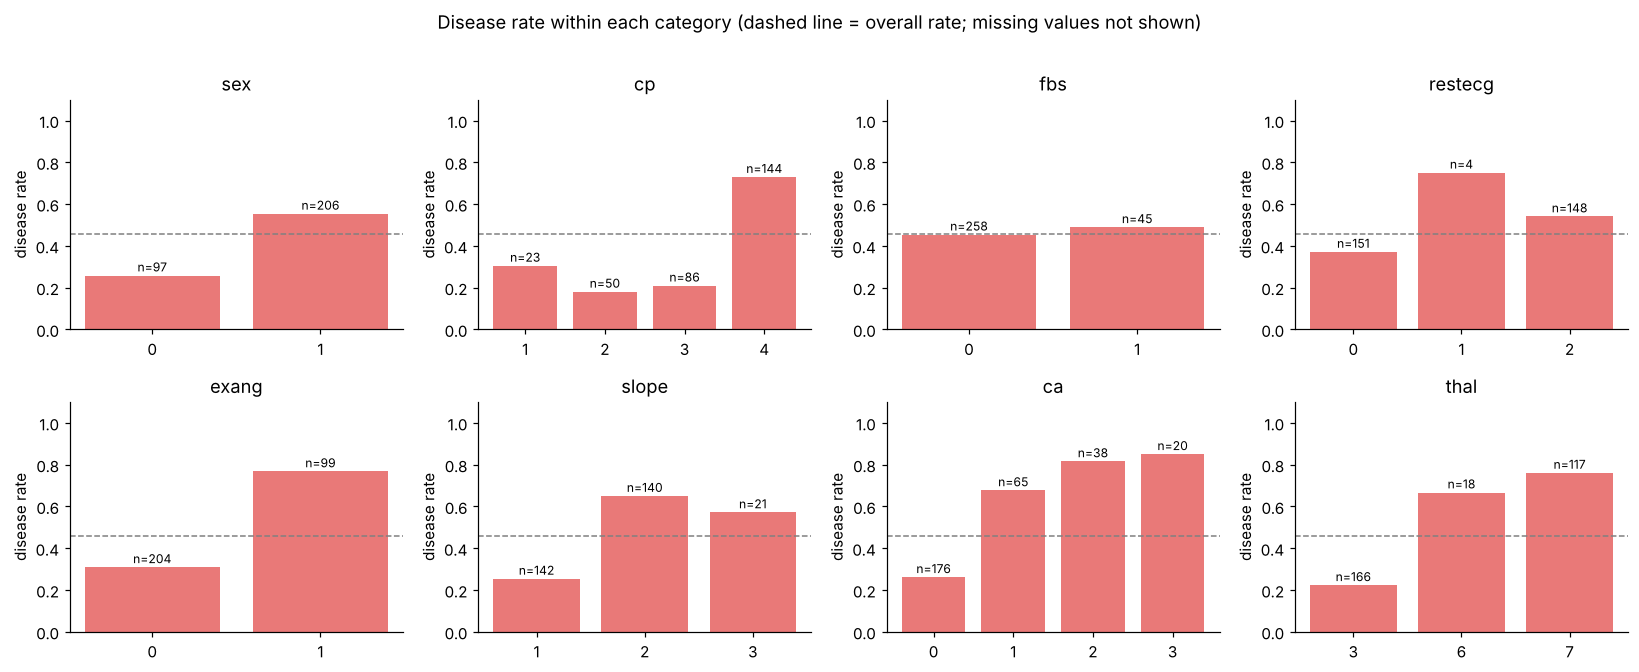

In [6]:
# ---- 4b. Disease rate per category ----------------------------------------
CAT_VIEW = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), CAT_VIEW):
    g = df.groupby(col)["target"].agg(["mean", "size"])
    ax.bar(g.index.astype(int).astype(str), g["mean"], color="#E45756", alpha=0.8)
    for i, (rate, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, rate + 0.02, f"n={n}", ha="center", fontsize=8)
    ax.axhline(df.target.mean(), ls="--", c="grey", lw=1)
    ax.set_ylim(0, 1.1); ax.set_title(col); ax.set_ylabel("disease rate")
fig.suptitle("Disease rate within each category (dashed line = overall rate; missing values not shown)", y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / "categorical_disease_rate.png", bbox_inches="tight"); plt.show()

In [7]:
# ---- 4c. Strength of each feature's association with the target -----------
# Spearman rank correlation: works for numeric and ordinal codes. For nominal
# features (cp, restecg, thal) the sign depends on the arbitrary coding, so
# read only the magnitude there.
assoc = (df.drop(columns="target")
           .corrwith(df["target"], method="spearman")
           .sort_values(key=np.abs, ascending=False)
           .to_frame("spearman_with_target"))
assoc

,spearman_with_target
thal,0.522
ca,0.489
cp,0.472
exang,0.432
thalach,-0.423
oldpeak,0.413
slope,0.364
sex,0.277
age,0.237
restecg,0.169


**What the EDA shows**
- **Exercise test features separate the classes most clearly.** Patients with disease reach a lower maximum heart rate (median 142 vs 161 bpm), show more ST depression (`oldpeak` median 1.4 vs 0.2) and much more often have exercise-induced angina (`exang`).
- **Fluoroscopy and thallium results are the strongest single signals.** The disease rate rises steadily with the number of colored vessels `ca` (0 to 3), and is far higher for a reversible thallium defect (`thal` = 7) than for a normal scan (`thal` = 3). These are the top two features by rank correlation.
- **Chest pain type looks counterintuitive.** "Asymptomatic" (`cp` = 4) has the highest disease rate (about 0.73) while typical angina (`cp` = 1) is low. A likely reason is referral: everyone here was sent for angiography, so a patient without typical chest pain was probably referred because something else had already raised suspicion. This is a hypothesis, not something this data can prove.
- **Weak signals:** resting blood pressure has the same median in both groups (130), cholesterol differs only slightly, and fasting blood sugar barely changes the disease rate. Men have a higher disease rate than women.
- `restecg` = 1 has only 4 patients, so its rate is not reliable. `slope` is not monotone (flat is higher than downsloping), which supports one-hot encoding it.

## 5. Preprocessing with leakage-free pipelines

Order of operations, which is what prevents leakage:
1. **Split first.** 80% train / 20% test, stratified on the target, fixed seed. The test set is not touched again until Section 7.
2. **Every preprocessing step lives inside a `Pipeline`** together with the model. `GridSearchCV` and `cross_validate` refit the whole pipeline on each training fold, so imputation values, scaling statistics and one-hot categories are always learned from the data the model trains on, never from the fold it is scored on.

Feature treatment:

| group | columns | steps | reason |
|---|---|---|---|
| continuous | age, trestbps, chol, thalach, oldpeak | median impute, standardize | SVM and Logistic Regression are scale-sensitive (distances, regularization penalty). Trees ignore scale, so this is harmless for them. |
| count | ca | median impute, standardize | Number of vessels 0 to 3 has a natural order, so it stays one ordinal column. |
| nominal | cp, restecg, slope, thal | most-frequent impute, one-hot | The integer codes are labels, not quantities (thal 7 is not "more" than 6). One-hot stops linear models and SVM from reading a fake order. `handle_unknown="ignore"` keeps the pipeline safe if a rare level is absent from a training fold. |
| binary | sex, fbs, exang | most-frequent impute, passthrough | Already 0/1. |

`slope` is technically ordered (up, flat, down), but its relationship with disease is not monotone in the EDA, so one-hot is the safer choice.

In [8]:
# ---- 5. Split, then build the preprocessing pipeline ----------------------
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("train:", X_train.shape, "positive share %.3f" % y_train.mean())
print("test :", X_test.shape, "positive share %.3f" % y_test.mean())

CONTINUOUS = ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
NOMINAL = ["cp", "restecg", "slope", "thal"]
BINARY = ["sex", "fbs", "exang"]


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), CONTINUOUS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))]), NOMINAL),
        ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
    ], verbose_feature_names_out=False)


# Sanity check: fit on the training set only and look at the output features
pre_check = make_preprocessor().fit(X_train)
print("\n%d features after preprocessing:" % len(pre_check.get_feature_names_out()))
print(list(pre_check.get_feature_names_out()))

train: (242, 13) positive share 0.459
test : (61, 13) positive share 0.459

22 features after preprocessing:
['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca', 'cp_1.0', 'cp_2.0', 'cp_3.0', 'cp_4.0', 'restecg_0.0', 'restecg_1.0', 'restecg_2.0', 'slope_1.0', 'slope_2.0', 'slope_3.0', 'thal_3.0', 'thal_6.0', 'thal_7.0', 'sex', 'fbs', 'exang']


## 6. Model tuning and nested cross-validation

**Search.** Each model gets a small, deliberate hyperparameter grid searched with `GridSearchCV` over 5 stratified folds. The search optimizes **ROC-AUC** because it measures how well the model ranks sick patients above healthy ones independently of any threshold; the threshold is chosen separately in Section 8 with recall as the priority. Tuning on recall directly would reward degenerate models that call everyone sick.

| model | searched | why these |
|---|---|---|
| Logistic Regression | C, class_weight | C controls L2 regularization strength, the main bias/variance knob on 242 training rows. |
| SVM | kernel (linear, RBF), C, gamma | Linear vs non-linear boundary, margin softness, RBF width. |
| Random Forest | max_depth, min_samples_leaf, max_features | Tree depth and leaf size are the main overfitting controls on small data. |
| XGBoost | n_estimators, max_depth, learning_rate, subsample | Shallow trees and a low learning rate suit a small tabular dataset. |

**Honest scores: nested cross-validation.** The best CV score reported by a grid search is optimistically biased, because the same folds were used to pick the hyperparameters. To report scores that are not inflated, I wrap the whole grid search in an outer loop: 5-fold stratified CV repeated 3 times (15 outer folds) on the training set. In each outer fold the grid search runs on the outer-training part only and is scored on the outer-held-out part. The mean and standard deviation over the 15 outer folds estimate how the full tuning procedure generalizes. Metrics here use the default 0.5 threshold.

In [9]:
# ---- 6a. Models and grids -------------------------------------------------
MODELS = {
    "Logistic Regression": (
        LogisticRegression(max_iter=5000, random_state=SEED),
        {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": [None, "balanced"]}),
    "SVM": (
        # SVC outputs margins, not probabilities. Platt scaling (sigmoid calibration on
        # internal CV folds) turns them into probabilities so thresholds and ROC curves are
        # comparable with the other models. This is the replacement sklearn recommends for
        # the deprecated SVC(probability=True).
        CalibratedClassifierCV(SVC(random_state=SEED), method="sigmoid", ensemble=False),
        [{"clf__estimator__kernel": ["linear"], "clf__estimator__C": [0.01, 0.1, 1]},
         {"clf__estimator__kernel": ["rbf"], "clf__estimator__C": [0.1, 1, 10],
          "clf__estimator__gamma": ["scale", 0.01, 0.1]}]),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
        {"clf__max_depth": [3, 6, None], "clf__min_samples_leaf": [1, 5],
         "clf__max_features": ["sqrt", 0.5]}),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, colsample_bytree=0.8),
        {"clf__n_estimators": [100, 300], "clf__max_depth": [2, 3],
         "clf__learning_rate": [0.03, 0.1], "clf__subsample": [0.8, 1.0]}),
}


def make_search(estimator, grid):
    pipe = Pipeline([("pre", make_preprocessor()), ("clf", estimator)])
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    return GridSearchCV(pipe, grid, scoring="roc_auc", cv=inner, n_jobs=-1)

In [10]:
# ---- 6b. Nested cross-validation on the training set ----------------------
SCORING = {"roc_auc": "roc_auc", "recall": "recall", "precision": "precision",
           "f1": "f1", "accuracy": "accuracy"}
outer = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

nested_rows = {}
for name, (est, grid) in MODELS.items():
    cv_res = cross_validate(make_search(est, grid), X_train, y_train,
                            cv=outer, scoring=SCORING, n_jobs=1)
    nested_rows[name] = {m: (cv_res[f"test_{m}"].mean(), cv_res[f"test_{m}"].std())
                         for m in SCORING}
    print(f"{name:20s} ROC-AUC {nested_rows[name]['roc_auc'][0]:.3f} "
          f"+/- {nested_rows[name]['roc_auc'][1]:.3f}")

nested_table = pd.DataFrame({name: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in r.items()}
                             for name, r in nested_rows.items()}).T
nested_table.index.name = "model"
print("Nested CV on the training set: 15 outer folds, mean ± std, threshold 0.5")
nested_table

Logistic Regression  ROC-AUC 0.892 +/- 0.044


SVM                  ROC-AUC 0.887 +/- 0.048


Random Forest        ROC-AUC 0.891 +/- 0.039


XGBoost              ROC-AUC 0.875 +/- 0.039
Nested CV on the training set: 15 outer folds, mean ± std, threshold 0.5


,roc_auc,recall,precision,f1,accuracy
model,,,,,
Logistic Regression,0.892 ± 0.044,0.780 ± 0.082,0.849 ± 0.082,0.808 ± 0.049,0.831 ± 0.043
SVM,0.887 ± 0.048,0.753 ± 0.085,0.837 ± 0.075,0.789 ± 0.062,0.817 ± 0.050
Random Forest,0.891 ± 0.039,0.771 ± 0.095,0.812 ± 0.070,0.787 ± 0.067,0.811 ± 0.054
XGBoost,0.875 ± 0.039,0.774 ± 0.093,0.790 ± 0.059,0.777 ± 0.055,0.799 ± 0.048


**Reading the nested CV table**
- All four models land within about 0.02 ROC-AUC of each other (0.875 to 0.892), while the fold-to-fold standard deviation is about 0.04. **The differences between models are smaller than the noise**, so no model is clearly better. Logistic Regression has the highest mean ROC-AUC and F1, essentially tied with Random Forest.
- This is typical for a small tabular dataset whose signal is mostly additive: the flexibility of boosting does not pay off on 242 rows.
- At the default 0.5 threshold, mean recall is only about 0.75 to 0.78: roughly one sick patient in four or five would be missed. Section 8 addresses this.
- In Section 7 the best inner-CV scores of the plain grid searches (0.896 to 0.908) are all higher than these nested scores. That gap is the optimistic bias of reusing the tuning folds for scoring, which is exactly why nested CV is reported here.

## 7. Test-set evaluation

Now each grid search is refit on the full training set (5-fold inner CV picks the hyperparameters), and the chosen pipeline is evaluated **once** on the 61 held-out test patients. With only about 28 sick patients in the test set, one patient changes recall by about 3.6 percentage points, so these single-split numbers are noisier than the nested CV numbers above. The nested CV table is the main basis for comparing models; the test set is a final sanity check.

In [11]:
# ---- 7. Refit on full training set, evaluate on the test set --------------
def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {"precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "accuracy": accuracy_score(y_true, pred)}

fitted, test_proba, test_rows, best_params = {}, {}, {}, {}
for name, (est, grid) in MODELS.items():
    search = make_search(est, grid).fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    best_params[name] = {k.replace("clf__", "").replace("estimator__", ""): v for k, v in search.best_params_.items()}
    test_proba[name] = search.predict_proba(X_test)[:, 1]
    test_rows[name] = metrics_at(y_test, test_proba[name], 0.5)
    print(f"{name:20s} inner-CV AUC {search.best_score_:.3f} | best params {best_params[name]}")

test_table = pd.DataFrame(test_rows).T[["precision", "recall", "f1", "roc_auc", "accuracy"]]
test_table.index.name = "test set (n=61), threshold 0.5"
test_table

Logistic Regression  inner-CV AUC 0.908 | best params {'C': 1, 'class_weight': 'balanced'}


SVM                  inner-CV AUC 0.904 | best params {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}


Random Forest        inner-CV AUC 0.898 | best params {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 5}


XGBoost              inner-CV AUC 0.896 | best params {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}


,precision,recall,f1,roc_auc,accuracy
"test set (n=61), threshold 0.5",,,,,
Logistic Regression,0.812,0.929,0.867,0.958,0.869
SVM,0.839,0.929,0.881,0.960,0.885
Random Forest,0.839,0.929,0.881,0.955,0.885
XGBoost,0.862,0.893,0.877,0.955,0.885


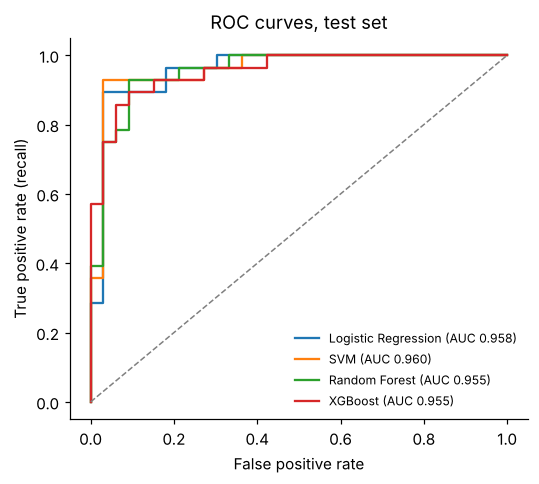

In [12]:
# ROC curves on the test set
fig, ax = plt.subplots(figsize=(5, 4.5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", c="grey", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves, test set"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "roc_test.png"); plt.show()

**Reading the test results.** Test ROC-AUC (0.955 to 0.960) is clearly higher than the nested CV estimate (about 0.89). With 61 patients this is most likely a favourable split rather than a better model, so the nested CV numbers are the ones to quote as the expected performance; the test set mainly confirms that nothing broke. Logistic Regression picked `class_weight="balanced"`, which slightly raises the weight of the disease class.

## 8. Decision threshold for a medical setting

**Why recall comes first.** In a screening setting the two errors have very different costs:
- A **false negative** tells a sick patient they are fine. They may skip follow-up and the disease progresses untreated, possibly to a heart attack. This harm is severe and may be irreversible.
- A **false positive** sends a healthy patient for further tests (stress echo, angiography). That costs money, time and anxiety, but the follow-up test catches the error.

So the model should catch as many sick patients as possible (high **recall**, also called sensitivity), accepting more false alarms (lower **precision**). The default 0.5 threshold has no medical meaning: it simply assumes both errors cost the same.

**Which model.** I pick the model with the best nested-CV ROC-AUC, because ROC-AUC measures ranking quality, which is exactly what we then exploit by moving the threshold.

**How the threshold is chosen, without touching the test set.** I generate out-of-fold probabilities on the training set (5-fold `cross_val_predict` of the tuned pipeline, so each training patient is scored by a model that did not see them). On those, I pick the **highest threshold that still achieves at least 90% recall**. The reasoning:
- 90% recall is the stated clinical target: the screen should miss at most about 1 in 10 sick patients. This target is a policy decision, not something the data can decide; a real deployment would set it with clinicians.
- Among thresholds meeting the target, the highest one keeps precision as high as possible, so we do not create more false alarms than needed.

The threshold is then frozen and applied to the test set.

Best model by nested CV ROC-AUC: Logistic Regression
At the default 0.5: out-of-fold train recall 0.829, precision 0.860
Chosen threshold: 0.316 (out-of-fold train recall 0.901, precision 0.730)


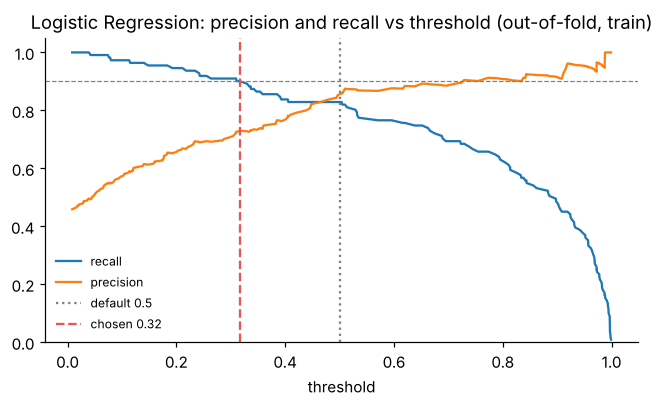

In [13]:
# ---- 8a. Choose best model and threshold on out-of-fold training predictions
nested_auc = {n: r["roc_auc"][0] for n, r in nested_rows.items()}
BEST = max(nested_auc, key=nested_auc.get)
print("Best model by nested CV ROC-AUC:", BEST)

TARGET_RECALL = 0.90
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_proba = cross_val_predict(fitted[BEST], X_train, y_train, cv=oof_cv,
                              method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
# precision_recall_curve returns len(thr) = len(prec) - 1; align by dropping the last point
prec, rec = prec[:-1], rec[:-1]
ok = rec >= TARGET_RECALL
THRESHOLD = float(thr[ok].max())
i = np.where(thr == THRESHOLD)[0][0]
oof05 = (oof_proba >= 0.5).astype(int)
print(f"At the default 0.5: out-of-fold train recall {recall_score(y_train, oof05):.3f}, "
      f"precision {precision_score(y_train, oof05):.3f}")
print(f"Chosen threshold: {THRESHOLD:.3f} "
      f"(out-of-fold train recall {rec[i]:.3f}, precision {prec[i]:.3f})")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(thr, rec, label="recall")
ax.plot(thr, prec, label="precision")
ax.axvline(0.5, ls=":", c="grey", label="default 0.5")
ax.axvline(THRESHOLD, ls="--", c="#E45756", label=f"chosen {THRESHOLD:.2f}")
ax.axhline(TARGET_RECALL, ls="--", c="grey", lw=0.8)
ax.set_xlabel("threshold"); ax.set_ylim(0, 1.05)
ax.set_title(f"{BEST}: precision and recall vs threshold (out-of-fold, train)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "threshold_choice.png"); plt.show()

,precision,recall,f1,roc_auc,accuracy
threshold 0.5,0.812,0.929,0.867,0.958,0.869
threshold 0.316,0.730,0.964,0.831,0.958,0.820


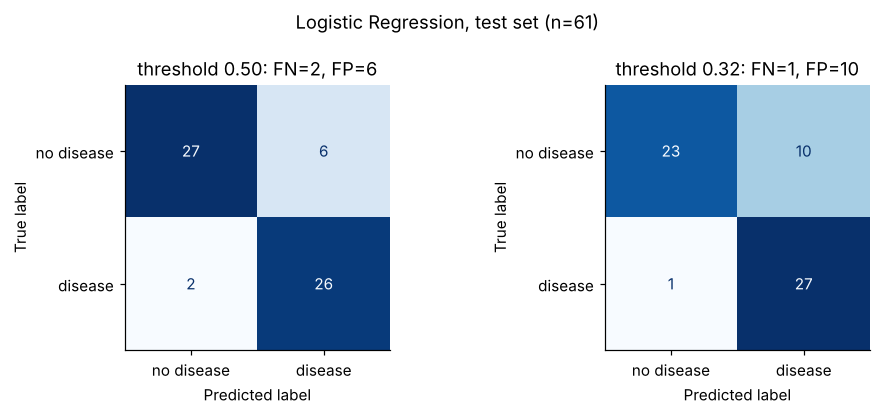

In [14]:
# ---- 8b. Apply the frozen threshold to the test set -----------------------
p = test_proba[BEST]
cmp = pd.DataFrame({"threshold 0.5": metrics_at(y_test, p, 0.5),
                    f"threshold {THRESHOLD:.3f}": metrics_at(y_test, p, THRESHOLD)}).T
display(cmp)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, t in zip(axes, [0.5, THRESHOLD]):
    cm = confusion_matrix(y_test, (p >= t).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["no disease", "disease"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"threshold {t:.2f}: FN={fn}, FP={fp}")
fig.suptitle(f"{BEST}, test set (n={len(y_test)})")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png"); plt.show()

**Result of the threshold choice**
- Logistic Regression is selected: it has the best nested-CV ROC-AUC (tied in practice with Random Forest), and it is the easiest model to explain and audit, which matters in a clinical context.
- The rule gives a threshold of about **0.32**. On the out-of-fold training predictions it reaches 90.1% recall at 73.0% precision, compared with 82.9% recall at 86.0% precision for the default 0.5. So on data the model had not seen, the default would miss about 1 sick patient in 6, the chosen threshold about 1 in 10.
- On the test set, lowering the threshold from 0.5 to 0.32 moves **false negatives from 2 to 1** and **false positives from 6 to 10**: recall rises from 0.929 to 0.964 while precision falls from 0.812 to 0.730. In words: one more sick patient is caught, at the cost of four more healthy patients being sent for follow-up tests. Given the asymmetric costs above, that is the trade we want.
- ROC-AUC does not change (0.958), as expected: the threshold changes decisions, not the ranking.
- Caveat: with 28 sick patients in the test set, "2 vs 1 missed" is a single patient. The more reliable evidence that the lower threshold helps is the out-of-fold curve above, built from 242 patients the model had not seen during each fit.

## 9. Interpretability

Two complementary views of the best model:
1. **Permutation importance on the test set**, computed on the *original* 13 features (the pipeline is permuted end to end, so one-hot columns of the same feature move together). It answers: how much does test ROC-AUC drop if this feature's information is destroyed?
2. **SHAP values**, which show for each patient how much each (preprocessed) feature pushed the prediction toward or away from disease, and in which direction.

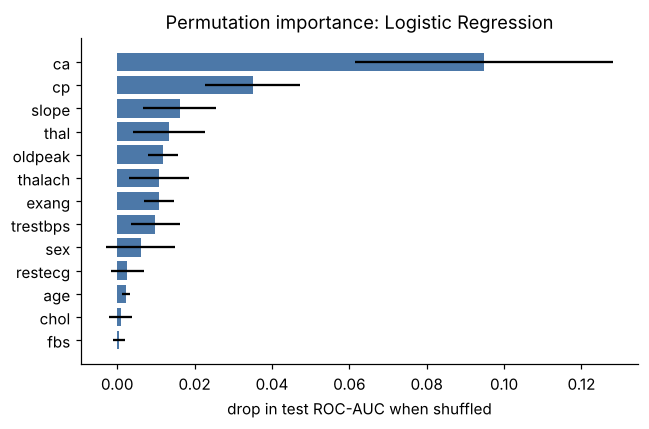

,mean_auc_drop,std
ca,9.477e-02,3.330e-02
cp,3.503e-02,1.226e-02
slope,1.613e-02,9.478e-03
thal,1.349e-02,9.309e-03
oldpeak,1.180e-02,3.804e-03
thalach,1.079e-02,7.792e-03
exang,1.079e-02,3.816e-03
trestbps,9.848e-03,6.319e-03
sex,6.097e-03,8.931e-03
restecg,2.633e-03,4.198e-03


In [15]:
# ---- 9a. Permutation importance (model-agnostic, original features) -------
perm = permutation_importance(fitted[BEST], X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=SEED, n_jobs=1)
perm_df = (pd.DataFrame({"mean_auc_drop": perm.importances_mean, "std": perm.importances_std},
                        index=X_test.columns)
             .sort_values("mean_auc_drop", ascending=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(perm_df.index[::-1], perm_df["mean_auc_drop"][::-1],
        xerr=perm_df["std"][::-1], color="#4C78A8")
ax.set_xlabel("drop in test ROC-AUC when shuffled")
ax.set_title(f"Permutation importance: {BEST}")
plt.tight_layout(); plt.savefig(FIG_DIR / "permutation_importance.png"); plt.show()
perm_df

Explainer: LinearExplainer


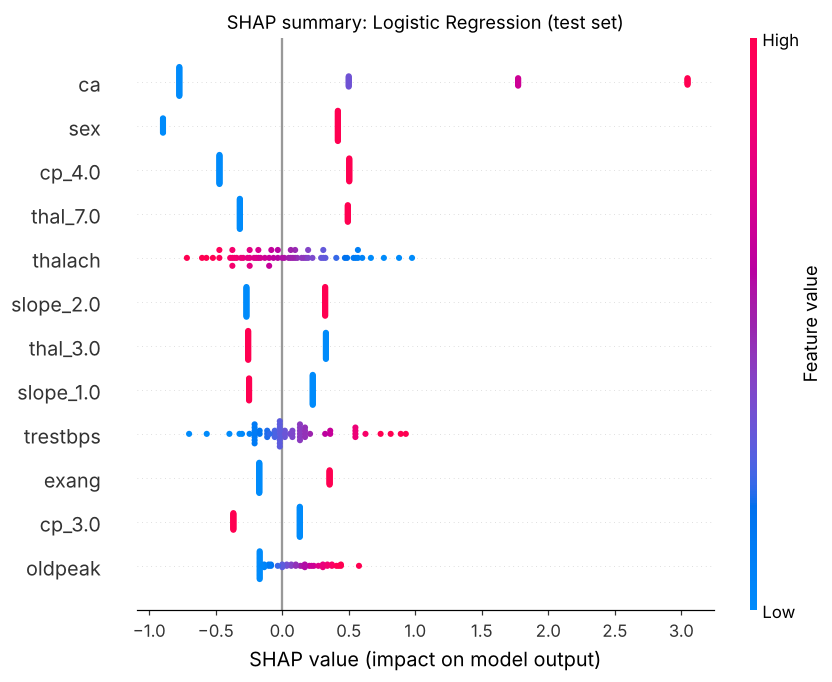

,mean_abs_shap
ca,1.165
sex,0.575
cp_4.0,0.486
thal_7.0,0.382
thalach,0.312
slope_2.0,0.295
thal_3.0,0.290
slope_1.0,0.238
trestbps,0.236
exang,0.233


In [16]:
# ---- 9b. SHAP for the best model ------------------------------------------
pre = fitted[BEST].named_steps["pre"]
clf = fitted[BEST].named_steps["clf"]
feat_names = pre.get_feature_names_out()
Xtr_t = pd.DataFrame(pre.transform(X_train), columns=feat_names, index=X_train.index)
Xte_t = pd.DataFrame(pre.transform(X_test), columns=feat_names, index=X_test.index)

# Pick the exact explainer that matches the model type
if isinstance(clf, LogisticRegression):
    # exact for linear models; values are in log-odds. Use the whole training set as background.
    explainer = shap.LinearExplainer(clf, shap.maskers.Independent(Xtr_t, max_samples=len(Xtr_t)))
    sv = explainer(Xte_t)
elif isinstance(clf, (RandomForestClassifier, XGBClassifier)):
    explainer = shap.TreeExplainer(clf)                   # exact for tree ensembles
    sv = explainer(Xte_t)
    if sv.values.ndim == 3:                               # RF returns one set per class
        sv = sv[:, :, 1]
else:                                                     # calibrated SVM: model-agnostic, slower
    bg = shap.kmeans(Xtr_t, 20)
    explainer = shap.KernelExplainer(lambda a: clf.predict_proba(a)[:, 1], bg)
    sv = shap.Explanation(explainer.shap_values(Xte_t, nsamples=300, silent=True),
                          data=Xte_t.values, feature_names=list(feat_names))
print("Explainer:", type(explainer).__name__)

shap.summary_plot(sv, Xte_t, show=False, max_display=12)
plt.title(f"SHAP summary: {BEST} (test set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_summary.png", bbox_inches="tight"); plt.show()

shap_rank = (pd.Series(np.abs(sv.values).mean(axis=0), index=feat_names)
               .sort_values(ascending=False).to_frame("mean_abs_shap"))
shap_rank.head(12)

In [17]:
# Model-native view for the linear case: coefficients on standardized / one-hot features
if hasattr(clf, "coef_"):
    coef = pd.Series(clf.coef_.ravel(), index=feat_names).sort_values(key=np.abs, ascending=False)
    display(coef.to_frame("coefficient (log-odds per unit)").head(12))
elif hasattr(clf, "feature_importances_"):
    display(pd.Series(clf.feature_importances_, index=feat_names)
              .sort_values(ascending=False).to_frame("impurity/gain importance").head(12))

,coefficient (log-odds per unit)
sex,1.314
ca,1.121
cp_4.0,0.976
thal_7.0,0.812
cp_1.0,-0.619
slope_2.0,0.592
thal_3.0,-0.584
exang,0.529
cp_3.0,-0.499
slope_1.0,-0.478


**Do the top features make clinical sense?** Mostly yes.
- **`ca` (vessels colored by fluoroscopy)** dominates both views. More visibly affected major vessels means more coronary artery disease, which is what the diagnosis measures, so this is expected. It also means the model leans on a result that is close to the diagnosis itself.
- **`thal` = 7 (reversible defect)** raises risk and **`thal` = 3 (normal)** lowers it. A reversible defect means part of the heart muscle is under-supplied during stress, a classic sign of ischemia.
- **Exercise test markers** behave as cardiology expects: lower maximum heart rate (`thalach`), exercise-induced angina (`exang`), a flat ST slope (`slope` = 2) and more ST depression (`oldpeak`) all push toward disease.
- **`cp` = 4 (asymptomatic)** raising risk is the one counterintuitive pattern, discussed in the EDA: it most likely reflects how these patients were referred, not biology.
- **`sex` (male)** has a large coefficient. Men do have higher coronary disease risk at a given age, but part of this effect is probably specific to this referred sample. Note that permutation importance for `sex` on the test set is small and noisy, so the two methods disagree on how much the model's test performance depends on it.
- **Age, cholesterol and fasting blood sugar contribute little.** They are well established long-term risk factors, so this does *not* mean they do not matter. The model already sees direct evidence of disease (fluoroscopy, thallium, exercise test), which absorbs most of what age and cholesterol would predict, and a single cholesterol reading is a noisy measurement.

Two cautions when reading these plots: importances describe **associations the model uses, not causes**; and SHAP values for a Logistic Regression are in log-odds, with each one-hot level (for example `cp_4.0`) shown separately rather than as one `cp` feature.

In [18]:
# ---- Save the numbers the README quotes, straight from this run -----------
summary = {
    "n_train": int(len(y_train)), "n_test": int(len(y_test)),
    "test_positives": int(y_test.sum()),
    "nested_cv": {n: {m: [round(mu, 4), round(sd, 4)] for m, (mu, sd) in r.items()}
                  for n, r in nested_rows.items()},
    "test_threshold_0.5": {n: {m: round(v, 4) for m, v in r.items()} for n, r in test_rows.items()},
    "best_params": {n: {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item())
                        for k, v in bp.items()} for n, bp in best_params.items()},
    "best_model": BEST, "target_recall": TARGET_RECALL, "threshold": round(THRESHOLD, 4),
    "best_model_test": {k: {m: round(v, 4) for m, v in row.items()} for k, row in cmp.T.to_dict().items()},
    "confusion_0.5": confusion_matrix(y_test, (p >= 0.5).astype(int)).tolist(),
    "confusion_chosen": confusion_matrix(y_test, (p >= THRESHOLD).astype(int)).tolist(),
    "permutation_top": perm_df["mean_auc_drop"].round(4).head(6).to_dict(),
    "shap_top": shap_rank["mean_abs_shap"].round(4).head(8).to_dict(),
}
(RES_DIR / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

{
  "n_train": 242,
  "n_test": 61,
  "test_positives": 28,
  "nested_cv": {
    "Logistic Regression": {
      "roc_auc": [
        0.8924,
        0.0437
      ],
      "recall": [
        0.78,
        0.0819
      ],
      "precision": [
        0.8492,
        0.0817
      ],
      "f1": [
        0.8078,
        0.0493
      ],
      "accuracy": [
        0.8306,
        0.0425
      ]
    },
    "SVM": {
      "roc_auc": [
        0.8869,
        0.0483
      ],
      "recall": [
        0.753,
        0.0853
      ],
      "precision": [
        0.8369,
        0.0754
      ],
      "f1": [
        0.7892,
        0.0617
      ],
      "accuracy": [
        0.817,
        0.0502
      ]
    },
    "Random Forest": {
      "roc_auc": [
        0.8914,
        0.0395
      ],
      "recall": [
        0.771,
        0.095
      ],
      "precision": [
        0.8117,
        0.0702
      ],
      "f1": [
        0.7875,
        0.0668
      ],
      "accuracy": [
        0.8114,


## 10. Limitations

- **Small sample.** 303 patients (61 in the test set). Test metrics move by several points per misclassified patient; the nested CV standard deviations show the real uncertainty.
- **Old, single-site data.** Collected at the Cleveland Clinic Foundation in the 1980s. Patient populations, referral patterns and diagnostic practice have changed, so performance on today's patients is unknown.
- **Selection bias.** These patients were already referred for angiography, so the disease rate (about 46%) is far higher than in the general population. Precision would be much lower in a general screening population, and the threshold would need re-tuning.
- **Some features come from tests that already point to the diagnosis.** `ca` (fluoroscopy) and `thal` (thallium scan) are themselves diagnostic procedures, so the model is not a cheap pre-test screen in its current form.
- **Binary target.** Severity grades 1 to 4 are merged; the model says nothing about how severe the disease is.
- **No external validation and no probability calibration check.** Both would be required before any real use.

**This is an educational model built for an internship task. It must not be used to make or support clinical decisions.**